# Cross-Dataset Evaluation: PGVIB Variants — Part A — ASVspoof 2021 (LA + DF)

Evaluates all PGVIB checkpoint variants on four held-out OOD datasets.

**Variants evaluated:**
- Monolithic VIB baseline (3 seeds, GLADAModel)
- Full per-group VIB (3 seeds, PerGroupVIBModel, s42 from phase_a_leaveout)
- g0-only VIB (3 seeds, PerGroupVIBModel(vib_disabled_groups=(1,2)))
- drop_vib_g0 (3 seeds, PerGroupVIBModel(vib_disabled_groups=(0,)))
- Cross-backbone: WavLM-Large g0-only (phase_pgvib_g0only, seed 42)
- Cross-backbone: xlsr-300m g0-only (phase_pgvib_replicate, seed 42)

**Datasets (held-out, never used in training):**
- ASVspoof 2021 LA — telephone/VoIP codec channel conditions
- ASVspoof 2021 DF — codec-post-processed deepfakes (social media conditions)
- WaveFake — neural vocoder diversity (6 vocoders, LJSpeech bonafide)
- CodecFake+ — LM-based neural codec TTS attacks (Encodec, SoundStream, ...)

**Output:** CSV at `MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results.csv`
with columns: variant, model_class, backbone, seed, dataset, eer, ci_low, ci_high,
auc, n_samples, checkpoint_path.

Self-contained: Run All from scratch. Missing checkpoints are skipped with a warning.
Results are written row-by-row so partial results survive session disconnects.

> **Split notebook (Part A).** ASVspoof 2021 LA + ASVspoof 2021 DF only. Runs concurrently with Part B. After both parts finish, run `cross_dataset_eval_pgvib_aggregate.ipynb` to merge `..._part_a.csv` + `..._part_b.csv` into the final tables.


## 1. Environment Setup


In [ ]:
!pip install -q transformers soundfile librosa scikit-learn tqdm safetensors

from google.colab import drive
drive.mount('/content/drive')

import torch
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print(f'GPU: {gpu.name} ({gpu.total_memory / 1e9:.1f} GB)')
else:
    raise RuntimeError('No GPU detected')


Mounted at /content/drive
GPU: NVIDIA A100-SXM4-80GB (85.1 GB)


## 2. Copy GLADA Package to Local Runtime


In [ ]:
import shutil, os, sys

CANDIDATES = [
    "/content/drive/Othercomputers/Jakob's MacBook Air/Thesis/298-deliverables/glada-code/glada",
    '/content/drive/MyDrive/Jakob/glada_pkg/glada',
    '/content/drive/MyDrive/Jakob/glada_pkg',
    '/content/drive/MyDrive/Jakob/glada',
]
DRIVE_PKG = next((c for c in CANDIDATES if os.path.exists(os.path.join(c, '__init__.py'))), None)
if DRIVE_PKG is None:
    raise FileNotFoundError(
        'No glada/__init__.py found in candidates. Run:\n'
        "  !find /content/drive -name '__init__.py' -path '*/glada/*' 2>/dev/null | head\n"
        'and add the parent directory to CANDIDATES above.'
    )

LOCAL_PKG = '/content/glada'
if os.path.exists(LOCAL_PKG): shutil.rmtree(LOCAL_PKG)
shutil.copytree(DRIVE_PKG, LOCAL_PKG)

for mod in list(sys.modules):
    if mod == 'glada' or mod.startswith('glada.'): del sys.modules[mod]
sys.path = [p for p in sys.path if 'glada' not in p]
if '/content' not in sys.path: sys.path.insert(0, '/content')
print(f'Package source: {DRIVE_PKG}\nCopied to:      {LOCAL_PKG}')


Package source: /content/drive/MyDrive/Jakob/glada_pkg/glada
Copied to:      /content/glada


## 3. Datasets (ASVspoof 2019 LA + ITW)


In [ ]:
import tarfile

def extract_dataset(tar_path, extract_to, name):
    if os.path.exists(extract_to) and len(os.listdir(extract_to)) > 0:
        print(f'{name}: already extracted to {extract_to}'); return
    os.makedirs(extract_to, exist_ok=True)
    print(f'{name}: extracting {tar_path} -> {extract_to} ...')
    with tarfile.open(tar_path) as t: t.extractall(extract_to)
    print(f'{name}: done.')

extract_dataset('/content/drive/MyDrive/Jakob/Datasets/LA.tar', '/content/data/asvspoof', 'ASVspoof 2019 LA')
extract_dataset('/content/drive/MyDrive/Jakob/Datasets/release_in_the_wild.tar', '/content/data/itw', 'In-the-Wild')

ASV_PROTO      = '/content/data/asvspoof/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
ASV_AUDIO      = '/content/data/asvspoof/LA/ASVspoof2019_LA_train/flac'
ASV_EVAL_PROTO = '/content/data/asvspoof/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt'
ASV_EVAL_AUDIO = '/content/data/asvspoof/LA/ASVspoof2019_LA_eval/flac'
ITW_META       = '/content/data/itw/release_in_the_wild/meta.csv'
ITW_AUDIO      = '/content/data/itw/release_in_the_wild'
for p in [ASV_PROTO, ASV_AUDIO, ASV_EVAL_PROTO, ITW_META]:
    assert os.path.exists(p), f'Missing: {p}'
print('Datasets verified.')


ASVspoof 2019 LA: extracting /content/drive/MyDrive/Jakob/Datasets/LA.tar -> /content/data/asvspoof ...


/tmp/ipykernel_19312/3241063313.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  with tarfile.open(tar_path) as t: t.extractall(extract_to)


ASVspoof 2019 LA: done.
In-the-Wild: extracting /content/drive/MyDrive/Jakob/Datasets/release_in_the_wild.tar -> /content/data/itw ...
In-the-Wild: done.
Datasets verified.


## 4. OOD Evaluation Dataset Paths (Part A: ASVspoof 2021 LA + DF)

ASVspoof 2021 LA and DF archives live on Drive. Reading large `.flac` trees
directly off Drive is too slow for evaluation, so we copy & extract the tarballs
to local runtime under `/content/data/asvspoof2021_*` (same pattern used for
2019 LA and ITW in section 3). A small sentinel file marks each archive as
already extracted, so re-running this cell after a session restart is cheap.

Archive layout on Drive:
```
Datasets/ASVspoof2021_LA/ASVspoof2021_LA_eval.tar.gz       -> ASVspoof2021_LA_eval/flac/
Datasets/ASVspoof2021_LA/LA-keys-full.tar.gz               -> keys/LA/CM/trial_metadata.txt
Datasets/ASVspoof2021_DF/ASVspoof2021_DF_eval_full.tar.gz  -> ASVspoof2021_DF_eval/flac/
Datasets/ASVspoof2021_DF/DF-keys-full.tar                  -> keys/DF/CM/trial_metadata.txt
```

WaveFake and CodecFake+ are evaluated by `cross_dataset_eval_pgvib_part_b.ipynb`
and are NOT extracted here (their paths are defined as stubs only, so the
DataLoader-build cell below stays symmetric across the two split notebooks).

**Never used during GLADA training or adaptation** — these are purely held-out
test sets for measuring cross-domain generalization (Muller et al., Interspeech 2022).


In [ ]:
import os, glob, shutil, tarfile, zipfile

# Sentinel-based archive extractor.  Each archive deposits a hidden marker
# file at <extract_to>/.extracted_<basename> on success, so we can extract
# multiple archives into the same directory (audio + keys for ASVspoof 2021)
# without confusing the "already extracted" check.  Auto-detects compression
# from the file extension (.tar/.tar.gz/.tar.bz2/.tar.xz/.zip).
def extract_archive(archive_path, extract_to, name):
    if not os.path.exists(archive_path):
        print(f'  [WARN] {name}: archive not found at {archive_path} — skipping')
        return False
    sentinel = os.path.join(extract_to, f'.extracted_{os.path.basename(archive_path)}')
    if os.path.exists(sentinel):
        print(f'  [SKIP] {name}: already extracted ({sentinel})')
        return True
    os.makedirs(extract_to, exist_ok=True)
    print(f'  {name}: extracting {archive_path} -> {extract_to} ...')
    if archive_path.endswith('.zip'):
        with zipfile.ZipFile(archive_path) as z:
            z.extractall(extract_to)
    else:
        # tarfile.open auto-detects .tar / .tar.gz / .tar.bz2 / .tar.xz.
        with tarfile.open(archive_path) as t:
            t.extractall(extract_to)
    open(sentinel, 'w').close()
    print(f'  {name}: done.')
    return True


def extract_split_archive(
    parts_glob, extract_to, name,
    scratch_dir='/content/data/_split_scratch',
):
    """Extract a tar.gz that was split into _part00.tar.gz / _part01.tar.gz /...
    chunks (e.g. via `split -b SIZE`).

    Use this when the canonical "_full" archive on Drive is truncated or
    missing.  The parts on Drive are NEVER modified — we copy each part to
    runtime scratch, concatenate them into one tarball, delete the per-part
    runtime copies (to free ~half the scratch usage), extract, and finally
    delete the concatenated archive.

    `cat part00 part01 ... > full.tar.gz` reproduces the original byte
    stream exactly when the parts came from `split -b ...` on the original
    .tar.gz, so tarfile then opens the reassembled archive normally.

    Disk profile (DF eval, ~80 GB across 4 parts, ~80 GB extracted FLAC):
      copy parts          ->  ~80 GB scratch
      concat              -> ~160 GB scratch (parts + concat)
      delete parts        ->  ~80 GB scratch (just concat)
      extract             -> ~80 GB scratch + ~80 GB extracted
      delete concat       -> ~80 GB extracted
    Comfortably fits Colab's 200 GB disk because FLAC barely compresses.
    """
    parts = sorted(glob.glob(parts_glob))
    if not parts:
        print(f'  [WARN] {name}: no parts matched {parts_glob} — skipping')
        return False
    sentinel = os.path.join(
        extract_to, f'.extracted_split_{os.path.basename(parts[0])}',
    )
    if os.path.exists(sentinel):
        print(f'  [SKIP] {name}: already extracted ({sentinel})')
        return True
    os.makedirs(extract_to, exist_ok=True)
    os.makedirs(scratch_dir, exist_ok=True)
    concat_path = os.path.join(
        scratch_dir,
        os.path.basename(parts[0]).replace('_part00', '_concat'),
    )

    # 1. Copy each part from Drive -> runtime scratch (skip if already there).
    local_parts = []
    for src in parts:
        dst = os.path.join(scratch_dir, os.path.basename(src))
        if not os.path.exists(dst) or os.path.getsize(dst) != os.path.getsize(src):
            print(f'  {name}: copying {os.path.basename(src)} '
                  f'({os.path.getsize(src) / 1e9:.1f} GB) -> {scratch_dir}')
            shutil.copy2(src, dst)
        local_parts.append(dst)

    # 2. Concatenate runtime parts into one tarball.
    print(f'  {name}: concatenating {len(local_parts)} parts -> {concat_path}')
    with open(concat_path, 'wb') as out:
        for p in local_parts:
            with open(p, 'rb') as inp:
                shutil.copyfileobj(inp, out, length=8 * 1024 * 1024)  # 8 MiB

    # 3. Delete the per-part runtime copies (Drive originals untouched).
    for p in local_parts:
        os.remove(p)
    print(f'  {name}: deleted {len(local_parts)} runtime parts '
          f'(Drive originals preserved)')

    # 4. Extract from the concatenated tarball.
    print(f'  {name}: extracting {concat_path} -> {extract_to}')
    with tarfile.open(concat_path) as t:
        t.extractall(extract_to)

    # 5. Delete the concatenated archive — frees the rest of scratch.
    os.remove(concat_path)
    open(sentinel, 'w').close()
    print(f'  {name}: done (concat archive deleted; only extracted tree remains).')
    return True


# ---- ASVspoof 2021 LA: extract audio + keys into one root ----
ASV21_LA_ROOT = '/content/data/asvspoof2021_la'
extract_archive(
    '/content/drive/MyDrive/Jakob/Datasets/ASVspoof2021_LA/ASVspoof2021_LA_eval.tar.gz',
    ASV21_LA_ROOT,
    'ASVspoof 2021 LA audio',
)
extract_archive(
    '/content/drive/MyDrive/Jakob/Datasets/ASVspoof2021_LA/LA-keys-full.tar.gz',
    ASV21_LA_ROOT,
    'ASVspoof 2021 LA keys',
)
ASV21_LA_KEYS  = f'{ASV21_LA_ROOT}/keys/LA/CM/trial_metadata.txt'
ASV21_LA_AUDIO = f'{ASV21_LA_ROOT}/ASVspoof2021_LA_eval/flac'

# ---- ASVspoof 2021 DF: extract audio (from split parts) + keys into one root ----
# `_full.tar.gz` on Drive is truncated (upload failure), so we reassemble
# the audio from the four `_part0N.tar.gz` chunks via extract_split_archive.
# Keys ship in a single .tar — extract normally.
ASV21_DF_ROOT = '/content/data/asvspoof2021_df'
extract_split_archive(
    '/content/drive/MyDrive/Jakob/Datasets/ASVspoof2021_DF/ASVspoof2021_DF_eval_part*.tar.gz',
    ASV21_DF_ROOT,
    'ASVspoof 2021 DF audio',
)
extract_archive(
    '/content/drive/MyDrive/Jakob/Datasets/ASVspoof2021_DF/DF-keys-full.tar',
    ASV21_DF_ROOT,
    'ASVspoof 2021 DF keys',
)
ASV21_DF_KEYS  = f'{ASV21_DF_ROOT}/keys/DF/CM/trial_metadata.txt'
ASV21_DF_AUDIO = f'{ASV21_DF_ROOT}/ASVspoof2021_DF_eval/flac'

# ---- Stub paths for Part B datasets (not extracted in this notebook) ----
WAVEFAKE_ROOT  = '/content/data/wavefake'
CODECFAKE_ROOT = '/content/data/codecfake'

# Verify paths exist — warn but do not hard-abort; missing datasets are
# skipped gracefully by the DataLoader-build cell below.
DATASET_PATHS = {
    '2021_LA':   (ASV21_LA_KEYS, ASV21_LA_AUDIO),
    '2021_DF':   (ASV21_DF_KEYS, ASV21_DF_AUDIO),
    'WaveFake':  (WAVEFAKE_ROOT,),
    'CodecFake': (CODECFAKE_ROOT,),
}
print()
for ds_name, paths in DATASET_PATHS.items():
    for p in paths:
        if os.path.exists(p):
            print(f'  OK   {ds_name}: {p}')
        else:
            print(f'  WARN {ds_name}: NOT FOUND — {p}')


  [SKIP] ASVspoof 2021 LA audio: already extracted (/content/data/asvspoof2021_la/.extracted_ASVspoof2021_LA_eval.tar.gz)
  [SKIP] ASVspoof 2021 LA keys: already extracted (/content/data/asvspoof2021_la/.extracted_LA-keys-full.tar.gz)
  ASVspoof 2021 DF audio: copying ASVspoof2021_DF_eval_part00.tar.gz (8.6 GB) -> /content/data/_split_scratch
  ASVspoof 2021 DF audio: copying ASVspoof2021_DF_eval_part01.tar.gz (8.6 GB) -> /content/data/_split_scratch
  ASVspoof 2021 DF audio: copying ASVspoof2021_DF_eval_part02.tar.gz (8.6 GB) -> /content/data/_split_scratch
  ASVspoof 2021 DF audio: copying ASVspoof2021_DF_eval_part03.tar.gz (8.7 GB) -> /content/data/_split_scratch
  ASVspoof 2021 DF audio: concatenating 4 parts -> /content/data/_split_scratch/ASVspoof2021_DF_eval_concat.tar.gz
  ASVspoof 2021 DF audio: deleted 4 runtime parts (Drive originals preserved)
  ASVspoof 2021 DF audio: extracting /content/data/_split_scratch/ASVspoof2021_DF_eval_concat.tar.gz -> /content/data/asvspoof2021_d

/tmp/ipykernel_19312/1411469703.py:98: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(extract_to)


  ASVspoof 2021 DF audio: done (concat archive deleted; only extracted tree remains).
  ASVspoof 2021 DF keys: extracting /content/drive/MyDrive/Jakob/Datasets/ASVspoof2021_DF/DF-keys-full.tar -> /content/data/asvspoof2021_df ...


/tmp/ipykernel_19312/1411469703.py:24: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(extract_to)


  ASVspoof 2021 DF keys: done.

  OK   2021_LA: /content/data/asvspoof2021_la/keys/LA/CM/trial_metadata.txt
  OK   2021_LA: /content/data/asvspoof2021_la/ASVspoof2021_LA_eval/flac
  OK   2021_DF: /content/data/asvspoof2021_df/keys/DF/CM/trial_metadata.txt
  OK   2021_DF: /content/data/asvspoof2021_df/ASVspoof2021_DF_eval/flac
  WARN WaveFake: NOT FOUND — /content/data/wavefake
  WARN CodecFake: NOT FOUND — /content/data/codecfake


## 3. Imports


In [ ]:
import gc, json, os, sys, time, warnings
import csv
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# GLADA package (copied in Section 1)
from glada import GLADAConfig, BACKBONE_REGISTRY, set_seed
from glada.models import GLADAModel
from glada.models.vib import VIBBottleneck
from glada.models.grl import GradientReversal
from glada.models.discriminators import GroupedLayerDomainDiscriminators
from glada.evaluation.metrics import compute_eer_with_ci

# OOD dataset classes — reuse existing loaders, do NOT reinvent.
from glada.datasets.asvspoof2021 import ASVspoof2021Dataset
from glada.datasets.wavefake import WaveFakeDataset
from glada.datasets.codecfake import CodecFakeDataset

print('Imports OK')


Imports OK


/content/glada/evaluation/evaluator.py:194: SyntaxWarning: invalid escape sequence '\p'
  it to ``\pm`` or the backslash will be lost in the output string.


## 4. PerGroupVIBModel Definition

Identical to the inline definition in `_phase_common.model_class_cells()`. Duplicated here
so this notebook is self-contained (Run All from scratch).

The `vib_disabled_groups` and `vib_betas` flags must match the flags used during training;
they are recorded in `VARIANTS` below and cross-checked against the checkpoint's state dict
shape before loading.


In [ ]:
class PerGroupVIBModel(GLADAModel):
    """GLADAModel with one VIBBottleneck per group, applied BEFORE the
    per-group discriminators. See _phase_common.model_class_cells() for full
    docstring and literature references (VIB: Alemi et al. 2017; GLADA: MLADA).

    This definition is duplicated here to keep the eval notebook self-contained.
    It must stay in sync with the training notebook definition in _phase_common.py.
    """

    def __init__(self, config, vib_disabled_groups=(), vib_betas=None):
        super().__init__(config)
        K = config.num_groups
        D = config.hidden_dim
        bd = config.bottleneck_dim
        self.group_vibs = nn.ModuleList([
            VIBBottleneck(2 * D, bd) for _ in range(K)
        ])
        self.group_compressed_proj = nn.Linear(K * bd, bd)
        if self.glada_disc is not None:
            self.glada_disc = GroupedLayerDomainDiscriminators(
                num_groups=K,
                input_dim=bd,
                hidden_dim=config.glada_disc_hidden,
            )
        for k in vib_disabled_groups:
            assert 0 <= k < K, f'vib_disabled_groups index {k} not in [0, {K})'
        self._vib_disabled = set(vib_disabled_groups)
        if vib_betas is not None:
            assert len(vib_betas) == K
            self.register_buffer('_vib_betas',
                torch.tensor(vib_betas, dtype=torch.float32))
        else:
            self._vib_betas = None

    def forward(self, input_values, attention_mask=None):
        backbone_frozen = not any(p.requires_grad for p in self.backbone.parameters())
        if backbone_frozen:
            with torch.no_grad():
                outputs = self.backbone(input_values, attention_mask=attention_mask, output_hidden_states=True)
        else:
            outputs = self.backbone(input_values, attention_mask=attention_mask, output_hidden_states=True)
        hidden_states = list(outputs.hidden_states)

        if attention_mask is not None:
            input_lengths = attention_mask.sum(dim=1)
            output_lengths = ((input_lengths - 1) // 320) + 1
            T = hidden_states[0].shape[1]
            frame_mask = (torch.arange(T, device=attention_mask.device).unsqueeze(0) < output_lengths.unsqueeze(1))
        else:
            frame_mask = None

        hidden_states = self.layer_norms(hidden_states)
        _, cka_loss, group_outputs = self.pooling(hidden_states, frame_mask=frame_mask)
        if not self.config.use_cka_loss:
            cka_loss = torch.tensor(0.0, device=group_outputs[0].device)

        z_groups = []
        kl_per_group = []
        for k, g_k in enumerate(group_outputs):
            if k in self._vib_disabled:
                z_k, _ = self.group_vibs[k](g_k, training=False)
                kl_k = torch.zeros((), device=g_k.device)
            else:
                z_k, kl_k = self.group_vibs[k](g_k, training=self.training)
            z_groups.append(z_k)
            kl_per_group.append(kl_k)

        if self._vib_betas is not None:
            kl_total = sum(self._vib_betas[k] * kl_per_group[k] for k in range(len(group_outputs)))
        else:
            kl_total = sum(kl_per_group) / max(len(group_outputs), 1)

        z_concat = torch.cat(z_groups, dim=-1)
        z = self.group_compressed_proj(z_concat)

        spoof_logits = self.task_classifier(z)
        result = {
            'spoof_logits': spoof_logits,
            'kl_loss': kl_total,
            'cka_loss': cka_loss,
            'features': z,
        }

        if self.glada_disc is not None:
            result['glada_domain_logits'] = self.glada_disc(z_groups, self.domain_grl_alpha)
            result['group_outputs'] = z_groups

        if self.domain_disc is not None:
            z_domain = GradientReversal.apply(z, self.domain_grl_alpha)
            result['domain_logits'] = self.domain_disc(z_domain)

        if self.speaker_adversary is not None:
            z_speaker = GradientReversal.apply(z, self.speaker_grl_alpha)
            result['speaker_logits'] = self.speaker_adversary(z_speaker)

        return result

print('PerGroupVIBModel defined.')


PerGroupVIBModel defined.


## 5. Variant Configuration

Each entry specifies:
- `phase_dir`: Drive subdirectory under `MyDrive/Jakob/Experiments/`
  (also used to locate the results JSON for best-epoch lookup)
- `results_json`: filename of the results JSON saved by the training notebook
- `model_class`: `'GLADAModel'` or `'PerGroupVIBModel'`
- `model_kwargs`: forwarded to `ModelCls(config, **model_kwargs)`
- `backbone`: SSL backbone name (default `wavlm-base-plus`)
- `seed`: training seed (used to reconstruct `GLADAConfig`)

**pergroup_vib_s42 and drop_vib_g0_s42** are from `phase_a_leaveout`, NOT
`phase_pgvib_replicate`. All other per-group / drop-g0 variants at seeds 123/456
are from `phase_pgvib_replicate`.


In [ ]:
DRIVE_EXP_BASE = '/content/drive/MyDrive/Jakob/Experiments'
OUTPUT_CSV     = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eval_pgvib_results_part_a.csv')

# -------------------------------------------------------------------------
# Variant table.  checkpoint_dir convention (set by GLADAConfig / base_trainer):
#   <phase_dir>/<variant_name>/<run_id>/checkpoint_epoch_<best_epoch>.pt
# The run_id is a timestamp string (YYYYmmdd_HHMMSS).  We glob for it.
# -------------------------------------------------------------------------
VARIANTS = {
    # ---- Monolithic VIB baseline (from phase_pgvib_monolithic) ----
    'monolithic_vib_s42': {
        'phase_dir':    'phase_pgvib_monolithic',
        'results_json': 'phase_pgvib_monolithic_results.json',
        'model_class':  'GLADAModel',
        'model_kwargs': {},
        'backbone':     'wavlm-base-plus',
        'seed':         42,
    },
    'monolithic_vib_s123': {
        'phase_dir':    'phase_pgvib_monolithic',
        'results_json': 'phase_pgvib_monolithic_results.json',
        'model_class':  'GLADAModel',
        'model_kwargs': {},
        'backbone':     'wavlm-base-plus',
        'seed':         123,
    },
    'monolithic_vib_s456': {
        'phase_dir':    'phase_pgvib_monolithic',
        'results_json': 'phase_pgvib_monolithic_results.json',
        'model_class':  'GLADAModel',
        'model_kwargs': {},
        'backbone':     'wavlm-base-plus',
        'seed':         456,
    },

    # ---- Full per-group VIB (s42 from phase_a_leaveout; s123/s456 from phase_pgvib_replicate) ----
    'pergroup_vib_s42': {
        'phase_dir':    'phase_a_leaveout',
        'variant_dir':  'sanity_no_disable',
        'results_json': 'phase_a_leaveout_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {},
        'backbone':     'wavlm-base-plus',
        'seed':         42,
    },
    'pergroup_vib_s123': {
        'phase_dir':    'phase_pgvib_replicate',
        'results_json': 'phase_pgvib_replicate_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {},
        'backbone':     'wavlm-base-plus',
        'seed':         123,
    },
    'pergroup_vib_s456': {
        'phase_dir':    'phase_pgvib_replicate',
        'results_json': 'phase_pgvib_replicate_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {},
        'backbone':     'wavlm-base-plus',
        'seed':         456,
    },

    # ---- g0-only VIB (phase_pgvib_g0only) ----
    'g0_only_vib_s42': {
        'phase_dir':    'phase_pgvib_g0only',
        'results_json': 'phase_pgvib_g0only_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (1, 2)},
        'backbone':     'wavlm-base-plus',
        'seed':         42,
    },
    'g0_only_vib_s123': {
        'phase_dir':    'phase_pgvib_g0only',
        'results_json': 'phase_pgvib_g0only_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (1, 2)},
        'backbone':     'wavlm-base-plus',
        'seed':         123,
    },
    'g0_only_vib_s456': {
        'phase_dir':    'phase_pgvib_g0only',
        'results_json': 'phase_pgvib_g0only_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (1, 2)},
        'backbone':     'wavlm-base-plus',
        'seed':         456,
    },

    # ---- drop_vib_g0 (s42 from phase_a_leaveout; s123/s456 from phase_pgvib_replicate) ----
    'drop_vib_g0_s42': {
        'phase_dir':    'phase_a_leaveout',
        'variant_dir':  'drop_vib_g0',
        'results_json': 'phase_a_leaveout_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (0,)},
        'backbone':     'wavlm-base-plus',
        'seed':         42,
    },
    'drop_vib_g0_s123': {
        'phase_dir':    'phase_pgvib_replicate',
        'results_json': 'phase_pgvib_replicate_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (0,)},
        'backbone':     'wavlm-base-plus',
        'seed':         123,
    },
    'drop_vib_g0_s456': {
        'phase_dir':    'phase_pgvib_replicate',
        'results_json': 'phase_pgvib_replicate_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (0,)},
        'backbone':     'wavlm-base-plus',
        'seed':         456,
    },

    # ---- Cross-backbone: WavLM-Large g0-only (phase_pgvib_g0only) ----
    # Large has 4 groups → vib_disabled_groups=(1, 2, 3)
    'g0_only_large_s42': {
        'phase_dir':    'phase_pgvib_g0only',
        'results_json': 'phase_pgvib_g0only_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (1, 2, 3)},
        'backbone':     'wavlm-large',
        'seed':         42,
    },

    # ---- Cross-backbone: xlsr-300m g0-only (phase_pgvib_replicate) ----
    # xlsr-300m has 4 groups → vib_disabled_groups=(1, 2, 3)
    'g0_only_xlsr_s42': {
        'phase_dir':    'phase_pgvib_replicate',
        'results_json': 'phase_pgvib_replicate_results.json',
        'model_class':  'PerGroupVIBModel',
        'model_kwargs': {'vib_disabled_groups': (1, 2, 3)},
        'backbone':     'xlsr-300m',
        'seed':         42,
    },
}

print(f'Total variants: {len(VARIANTS)}')
for name, spec in VARIANTS.items():
    print(f'  {name:<28s} cls={spec["model_class"]:<18s} backbone={spec["backbone"]:<20s} seed={spec["seed"]}')


Total variants: 14
  monolithic_vib_s42           cls=GLADAModel         backbone=wavlm-base-plus      seed=42
  monolithic_vib_s123          cls=GLADAModel         backbone=wavlm-base-plus      seed=123
  monolithic_vib_s456          cls=GLADAModel         backbone=wavlm-base-plus      seed=456
  pergroup_vib_s42             cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=42
  pergroup_vib_s123            cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=123
  pergroup_vib_s456            cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=456
  g0_only_vib_s42              cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=42
  g0_only_vib_s123             cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=123
  g0_only_vib_s456             cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=456
  drop_vib_g0_s42              cls=PerGroupVIBModel   backbone=wavlm-base-plus      seed=42
  drop_vib_g0_s123             cls=PerGroupVIBModel   b

## 6. Checkpoint Resolution Helpers

Two helpers:
1. `find_best_checkpoint(phase_dir, results_json, variant_name)` — reads the phase
   results JSON, extracts `best_eer`'s epoch, then globs for a matching checkpoint file.
2. `load_model(variant_name, spec, device)` — constructs a `GLADAConfig`, instantiates
   the right model class, loads state dict, and returns the model in eval mode.

Checkpoint naming convention (from `base_trainer.py`):
  `<DRIVE_EXP_BASE>/<phase_dir>/<variant_name>/<run_id>/checkpoint_epoch_<N>.pt`
The `run_id` is a timestamp; we glob `<variant_name>/*/checkpoint_epoch_<N>.pt`.
If multiple run_ids exist (re-runs), we take the most recent one.


In [ ]:
MODEL_CLASSES = {'GLADAModel': GLADAModel, 'PerGroupVIBModel': PerGroupVIBModel}


def find_best_checkpoint(phase_dir, variant_dir):
    """Locate the best checkpoint for a variant.

    Prefers `best_model.pt` (canonical best-EER snapshot, always saved with
    the embedded config dict). Falls back to the newest `ckpt_ep*.pt`
    periodic checkpoint if best_model.pt is missing. We do NOT use
    best_model.safetensors here because it has no embedded GLADAConfig
    and we need it to rebuild the model with the trained structural
    hyperparameters (num_speakers, num_groups, hidden_dim, ...).
    """
    import glob as _glob
    phase_path = os.path.join(DRIVE_EXP_BASE, phase_dir)
    var_path   = os.path.join(phase_path, variant_dir)

    matches = sorted(
        _glob.glob(os.path.join(var_path, '*', 'best_model.pt')),
        key=os.path.getmtime,
    )
    if matches:
        return matches[-1]

    matches = sorted(
        _glob.glob(os.path.join(var_path, '*', 'ckpt_ep*.pt')),
        key=os.path.getmtime,
    )
    if matches:
        print(f'  [INFO] no best_model.pt under {var_path}; using newest periodic '
              f'ckpt: {os.path.basename(matches[-1])}')
        return matches[-1]

    print(f'  [WARN] no checkpoint found under {var_path}')
    return None


def _state_dict_from(ckpt):
    """Unwrap whichever key the trainer used."""
    if isinstance(ckpt, dict):
        if 'model' in ckpt and isinstance(ckpt['model'], dict):
            return ckpt['model']
        if 'model_state_dict' in ckpt:
            return ckpt['model_state_dict']
    return ckpt


def load_model(variant_name, spec, device):
    """Instantiate, load state dict, return model in eval mode.

    The trainer wraps `asdict(self.config)` under the key `'config'`
    inside each .pt checkpoint (base_trainer.py:_save_checkpoint). We
    rebuild GLADAConfig from that dict so structural fields trained into
    the checkpoint (num_speakers, num_groups, hidden_dim, bottleneck_dim,
    backbone) match the saved tensors. Without this step, defaults like
    num_speakers=107 collide with the trained num_speakers=20 and
    load_state_dict fails on speaker_adversary.6.

    `variant_dir` (in spec) overrides `variant_name` for path resolution
    when the on-disk directory was named differently from the dict key.

    Returns:
        (model, ckpt_path, config) or (None, None, None) if loading failed.
    """
    variant_dir = spec.get('variant_dir', variant_name)
    ckpt_path = find_best_checkpoint(spec['phase_dir'], variant_dir)
    if ckpt_path is None:
        return None, None, None

    try:
        ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    except Exception as e:
        print(f'  [ERROR] torch.load failed for {ckpt_path}: {e}')
        return None, None, None

    cfg_dict = ckpt.get('config', {}) if isinstance(ckpt, dict) else {}
    # Restrict to fields GLADAConfig actually accepts (forward-compat with
    # added/removed fields between training and analysis).
    valid_fields = {k: v for k, v in cfg_dict.items()
                    if k in GLADAConfig.__dataclass_fields__}
    # Override eval-time settings without disturbing structural fields.
    valid_fields['experiment_name'] = variant_name
    valid_fields['batch_size']      = 64
    valid_fields['num_workers']     = 0
    valid_fields['seed']            = spec['seed']
    valid_fields['backbone']        = spec['backbone']
    cfg = GLADAConfig(**valid_fields)

    ModelCls = MODEL_CLASSES[spec['model_class']]
    model_kwargs = spec.get('model_kwargs', {})

    try:
        model = ModelCls(cfg, **model_kwargs).to(device)
        state_dict = _state_dict_from(ckpt)
        missing, unexpected = model.load_state_dict(state_dict, strict=False)
        if missing:
            print(f'  [INFO] {variant_name}: {len(missing)} missing keys (e.g. {list(missing)[:3]})')
        if unexpected:
            print(f'  [INFO] {variant_name}: {len(unexpected)} unexpected keys')
        model.eval()
        n_params = sum(p.numel() for p in model.parameters())
        print(f'  Loaded {variant_name}: {n_params:,} params  '
              f'(num_speakers={cfg.num_speakers}, num_groups={cfg.num_groups})  '
              f'from {ckpt_path}')
        return model, ckpt_path, cfg
    except Exception as e:
        import traceback; traceback.print_exc()
        print(f'  [ERROR] failed to load {variant_name}: {e}')
        return None, None, None


## 7. Build OOD DataLoaders

Constructs a DataLoader for each available OOD dataset.
Datasets whose paths do not exist on Drive are skipped with a warning — the
eval loop below handles missing loaders gracefully.

batch_size=64 for inference (larger than training batch_size=24-64) since we
have no optimizer state and can afford more GPU memory per forward pass.
num_workers=0 per project rule (Colab multiprocessing issues).


In [ ]:
DATASETS_TO_RUN = ['2021_LA', '2021_DF']  # split: this notebook is the part_a half
EVAL_BATCH_SIZE = 64
MAX_LEN = 64000  # 4 seconds at 16 kHz — matches training

eval_loaders = {}  # dataset_name -> DataLoader (or None if unavailable)

# ---- ASVspoof 2021 LA ----
try:
    if '2021_LA' in DATASETS_TO_RUN and os.path.exists(ASV21_LA_KEYS) and os.path.exists(ASV21_LA_AUDIO):
        ds_2021_la = ASVspoof2021Dataset(
            keys_path=ASV21_LA_KEYS,
            audio_dir=ASV21_LA_AUDIO,
            max_len=MAX_LEN,
        )
        eval_loaders['2021_LA'] = DataLoader(
            ds_2021_la, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0,
        )
    else:
        print('[WARN] ASVspoof 2021 LA not found — skipping.')
except Exception as e:
    print(f'[WARN] ASVspoof 2021 LA load error: {e}')

# ---- ASVspoof 2021 DF ----
try:
    if '2021_DF' in DATASETS_TO_RUN and os.path.exists(ASV21_DF_KEYS) and os.path.exists(ASV21_DF_AUDIO):
        ds_2021_df = ASVspoof2021Dataset(
            keys_path=ASV21_DF_KEYS,
            audio_dir=ASV21_DF_AUDIO,
            max_len=MAX_LEN,
        )
        eval_loaders['2021_DF'] = DataLoader(
            ds_2021_df, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0,
        )
    else:
        print('[WARN] ASVspoof 2021 DF not found — skipping.')
except Exception as e:
    print(f'[WARN] ASVspoof 2021 DF load error: {e}')

# ---- WaveFake ----
try:
    if 'WaveFake' in DATASETS_TO_RUN and os.path.exists(WAVEFAKE_ROOT):
        ds_wavefake = WaveFakeDataset(
            root_dir=WAVEFAKE_ROOT,
            max_len=MAX_LEN,
        )
        if len(ds_wavefake) > 0:
            eval_loaders['WaveFake'] = DataLoader(
                ds_wavefake, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0,
            )
        else:
            print('[WARN] WaveFake dataset is empty — skipping.')
    else:
        print('[WARN] WaveFake root not found — skipping.')
except Exception as e:
    print(f'[WARN] WaveFake load error: {e}')

# ---- CodecFake+ ----
try:
    if 'CodecFake' in DATASETS_TO_RUN and os.path.exists(CODECFAKE_ROOT):
        ds_codecfake = CodecFakeDataset(
            root_dir=CODECFAKE_ROOT,
            max_len=MAX_LEN,
        )
        if len(ds_codecfake) > 0:
            eval_loaders['CodecFake'] = DataLoader(
                ds_codecfake, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=0,
            )
        else:
            print('[WARN] CodecFake+ dataset is empty — skipping.')
    else:
        print('[WARN] CodecFake+ root not found — skipping.')
except Exception as e:
    print(f'[WARN] CodecFake+ load error: {e}')

print(f'\nAvailable eval loaders: {list(eval_loaders.keys())}')
for name, loader in eval_loaders.items():
    print(f'  {name}: {len(loader.dataset):,} samples, {len(loader)} batches')


  ASVspoof 2021: 181566 samples (18452 bonafide, 163114 spoof)
  ASVspoof 2021: 611829 samples (22617 bonafide, 589212 spoof)
[WARN] WaveFake root not found — skipping.
[WARN] CodecFake+ root not found — skipping.

Available eval loaders: ['2021_LA', '2021_DF']
  2021_LA: 181,566 samples, 2837 batches
  2021_DF: 611,829 samples, 9560 batches


## 8. Main Evaluation Loop

For each variant x dataset:
1. Load best checkpoint (skips gracefully if not found).
2. Run inference — `model.eval()` + `torch.no_grad()`. BF16 AMP on A100,
   float16 on T4 (the evaluator handles dtype selection).
3. Compute EER + AUC via `glada.evaluation.metrics.compute_eer_with_ci`
   (1000 bootstrap resamples for 95% CI — required for committee-ready results).
4. Append a row to the CSV and free GPU memory.

Primary metric: EER (Equal Error Rate, lower is better; 50% = chance).
Secondary metric: AUC-ROC (higher is better).
Both established in the ASVspoof challenge series (Yamagishi et al., 2021).


In [11]:
@torch.no_grad()
def run_inference(model, loader, device, use_bf16=True):
    """Collect scores and labels from a DataLoader.

    Uses AMP (bfloat16 on A100 / float16 on T4) to match training-time
    numerical precision. BFloat16 tensors must be cast to float32 before
    numpy conversion (known PyTorch limitation; see evaluator.py comments).

    Returns:
        scores (np.ndarray): bonafide probability P(class=1|x)
        labels (np.ndarray): ground truth (0=spoof, 1=bonafide)
    """
    model.eval()
    amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
    scores_list, labels_list = [], []
    for batch in tqdm(loader, leave=False):
        inp  = batch['input_values'].to(device, non_blocking=True)
        mask = batch['attention_mask'].to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=True, dtype=amp_dtype):
            out = model(inp, attention_mask=mask)
        # Bonafide probability: P(class=1 | x) via softmax over spoof_logits.
        probs = F.softmax(out['spoof_logits'], dim=1)[:, 1]
        # Cast to float32 before numpy conversion (BF16 limitation).
        scores_list.extend(probs.float().cpu().numpy())
        labels_list.extend(batch['task_label'].numpy())
    return np.array(scores_list), np.array(labels_list)


# ---- Setup ----
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_bf16 = torch.cuda.is_bf16_supported() if torch.cuda.is_available() else False
print(f'Device: {device}  BF16: {use_bf16}')

# CSV output: initialize with header.
CSV_COLUMNS = ['variant', 'model_class', 'backbone', 'seed', 'dataset',
               'eer', 'ci_low', 'ci_high', 'auc', 'n_samples', 'checkpoint_path']
if not os.path.exists(OUTPUT_CSV):
    with open(OUTPUT_CSV, 'w', newline='') as f:
        csv.writer(f).writerow(CSV_COLUMNS)
    print(f'Created CSV: {OUTPUT_CSV}')
else:
    print(f'Appending to existing CSV: {OUTPUT_CSV}')

# ---- Main loop ----
all_rows = []
loop_start = time.time()

for v_idx, (variant_name, spec) in enumerate(VARIANTS.items()):
    print(f'\n{"="*60}')
    print(f'[{v_idx+1}/{len(VARIANTS)}] {variant_name}')
    print(f'  model_class={spec["model_class"]}  backbone={spec["backbone"]}  seed={spec["seed"]}')

    # Load checkpoint — skip gracefully if not found.
    model, ckpt_path, cfg = load_model(variant_name, spec, device)
    if model is None:
        print(f'  [SKIP] {variant_name} — checkpoint not available.')
        continue

    # Evaluate on each available OOD dataset.
    for ds_name, loader in eval_loaders.items():
        t0 = time.time()
        try:
            scores, labels = run_inference(model, loader, device, use_bf16=use_bf16)
            metrics = compute_eer_with_ci(labels, scores, n_bootstrap=1000)
            elapsed = time.time() - t0
            print(
                f'  {ds_name:<12s}: EER={metrics["eer"]:.2f}%  '
                f'CI=[{metrics["ci_low"]:.2f}, {metrics["ci_high"]:.2f}]  '
                f'AUC={metrics["auc"]:.4f}  n={metrics["acc"]:.0f}%acc  '
                f'({elapsed:.0f}s)'
            )
            row = {
                'variant':         variant_name,
                'model_class':     spec['model_class'],
                'backbone':        spec['backbone'],
                'seed':            spec['seed'],
                'dataset':         ds_name,
                'eer':             round(metrics['eer'], 4),
                'ci_low':          round(metrics['ci_low'], 4),
                'ci_high':         round(metrics['ci_high'], 4),
                'auc':             round(metrics['auc'], 6),
                'n_samples':       len(labels),
                'checkpoint_path': ckpt_path,
            }
            all_rows.append(row)
            # Write immediately so partial results survive session disconnects.
            with open(OUTPUT_CSV, 'a', newline='') as f:
                w = csv.DictWriter(f, fieldnames=CSV_COLUMNS)
                w.writerow(row)
        except Exception as e:
            import traceback; traceback.print_exc()
            print(f'  [ERROR] {variant_name} x {ds_name}: {e}')

    # Free GPU memory between checkpoints.
    del model
    torch.cuda.empty_cache(); gc.collect()

total_min = (time.time() - loop_start) / 60
print(f'\nEval complete: {len(all_rows)} rows in {total_min:.1f} min')
print(f'Results: {OUTPUT_CSV}')


Device: cuda  BF16: True
Appending to existing CSV: /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_a.csv

[1/14] monolithic_vib_s42
  model_class=GLADAModel  backbone=wavlm-base-plus  seed=42


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

  Loaded monolithic_vib_s42: 100,738,076 params  (num_speakers=20, num_groups=3)  from /content/drive/MyDrive/Jakob/Experiments/phase_pgvib_monolithic/monolithic_vib_s42/20260507_192442/best_model.pt


... (103 outputs left out)

  0%|          | 0/2837 [00:00<?, ?it/s]

  2021_LA     : EER=27.26%  CI=[27.05, 27.45]  AUC=0.8435  n=56%acc  (631s)


  0%|          | 0/9560 [00:00<?, ?it/s]

  2021_DF     : EER=44.25%  CI=[44.15, 44.35]  AUC=0.5985  n=16%acc  (1764s)

Eval complete: 26 rows in 378.4 min
Results: /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_a.csv


## 9. Summary Table

Groups results by condition (model_class + backbone) and computes
multi-seed mean ± std for each (condition, dataset) pair.
Print order: conditions as rows, datasets as columns.


In [12]:
import statistics

if not all_rows:
    print('No results to summarize — all variants were skipped or failed.')
else:
    # Build pandas-like table from raw rows.
    import collections
    # Group by (model_class, backbone, dataset) -> list of EERs
    groups = collections.defaultdict(list)
    for row in all_rows:
        key = (row['model_class'], row['backbone'], row['dataset'])
        groups[key].append(row['eer'])

    ds_names = list(eval_loaders.keys()) if eval_loaders else ['2021_LA', '2021_DF', 'WaveFake', 'CodecFake']

    # Header
    col_w = 14
    header = f'{"condition":<38s}' + ''.join(f'{d:>{col_w}s}' for d in ds_names)
    print(header)
    print('-' * len(header))

    # Unique conditions (ordered by first appearance)
    seen_conditions = []
    condition_of = {}  # variant -> (model_class, backbone)
    for row in all_rows:
        cond = (row['model_class'], row['backbone'])
        condition_of[row['variant']] = cond
        if cond not in seen_conditions:
            seen_conditions.append(cond)

    for cond in seen_conditions:
        label = f'{cond[0]} / {cond[1]}'
        cells = []
        for ds in ds_names:
            key = (*cond, ds)
            eers = groups.get(key, [])
            if not eers:
                cells.append('-')
            elif len(eers) == 1:
                cells.append(f'{eers[0]:.2f}')
            else:
                m = statistics.mean(eers)
                s = statistics.stdev(eers)
                cells.append(f'{m:.2f}±{s:.2f}')
        row_str = f'{label:<38s}' + ''.join(f'{c:>{col_w}s}' for c in cells)
        print(row_str)

    print()
    print('Format: mean (EER%) or mean±std across seeds. Lower is better.')
    print(f'Full results at: {OUTPUT_CSV}')


condition                                    2021_LA       2021_DF
------------------------------------------------------------------
GLADAModel / wavlm-base-plus              28.69±0.65    44.04±0.01
PerGroupVIBModel / wavlm-base-plus        29.40±1.73    43.93±0.11
PerGroupVIBModel / wavlm-large                 27.26         43.81
PerGroupVIBModel / xlsr-300m                   27.26         44.25

Format: mean (EER%) or mean±std across seeds. Lower is better.
Full results at: /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_a.csv


# Cross-Dataset Evaluation: PGVIB Variants — Aggregator

Merges the two split notebooks' CSV outputs and produces:

1. **Cross-dataset EER table** — mean ± std across seeds, per condition × dataset.
2. **Per-group VIB vs Monolithic deltas** — does PGVIB help on each held-out set?
3. **Aggregate verdict** — single-line decision rule for the thesis chapter.
4. **Visualizations** — per-dataset bar chart and a condition × dataset heatmap.

**Inputs:**
- `MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_a.csv` (2021 LA + 2021 DF)
- `MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_b.csv` (WaveFake + CodecFake+)

**Outputs:**
- `MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_summary.csv` — combined long table.
- `MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_pivot.csv` — condition × dataset pivot (for thesis).
- Inline figures: `cross_dataset_eer_bars.png`, `cross_dataset_eer_heatmap.png`.

Run this **after** both `cross_dataset_eval_pgvib_part_a.ipynb` and `_part_b.ipynb`
have finished writing their CSVs.


## 1. Setup

In [13]:
import os
DRIVE_EXP_BASE = '/content/drive/MyDrive/Jakob/Experiments'
PART_A_CSV = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eval_pgvib_results_part_a.csv')
PART_B_CSV = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eval_pgvib_results_part_b.csv')

for p in [PART_A_CSV, PART_B_CSV]:
    print(('OK   ' if os.path.exists(p) else 'MISS ') + p)

OK   /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_a.csv
OK   /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_results_part_b.csv


## 2. Load + concatenate both halves

In [14]:
import pandas as pd

frames = []
for label, path in [('part_a', PART_A_CSV), ('part_b', PART_B_CSV)]:
    if not os.path.exists(path):
        print(f'[WARN] {label}: {path} missing — skipping.')
        continue
    df = pd.read_csv(path)
    df['source_part'] = label
    frames.append(df)

assert frames, 'No input CSVs found — run part_a and/or part_b first.'
df = pd.concat(frames, ignore_index=True)

# Sanity: no dataset should appear in both parts.
overlap = (
    df.groupby('dataset')['source_part']
      .nunique()
      .pipe(lambda s: s[s > 1])
)
if not overlap.empty:
    print(f'[WARN] Datasets present in both parts (will use both rows): {list(overlap.index)}')

print(f'Loaded {len(df)} rows; datasets: {sorted(df["dataset"].unique())}')
df.head()


Loaded 52 rows; datasets: ['2021_DF', '2021_LA', 'CodecFake', 'WaveFake']


,variant,model_class,backbone,seed,dataset,eer,ci_low,ci_high,auc,n_samples,checkpoint_path,source_part
0,monolithic_vib_s42,GLADAModel,wavlm-base-plus,42,2021_LA,29.3814,29.1279,29.6374,0.818672,181566,/content/drive/MyDrive/Jakob/Experiments/phase...,part_a
1,monolithic_vib_s42,GLADAModel,wavlm-base-plus,42,2021_DF,44.0368,43.9485,44.1254,0.602144,611829,/content/drive/MyDrive/Jakob/Experiments/phase...,part_a
2,monolithic_vib_s123,GLADAModel,wavlm-base-plus,123,2021_LA,28.5967,28.3619,28.8328,0.825818,181566,/content/drive/MyDrive/Jakob/Experiments/phase...,part_a
3,monolithic_vib_s123,GLADAModel,wavlm-base-plus,123,2021_DF,44.0483,43.9666,44.1427,0.601843,611829,/content/drive/MyDrive/Jakob/Experiments/phase...,part_a
4,monolithic_vib_s456,GLADAModel,wavlm-base-plus,456,2021_LA,28.0943,27.8556,28.3197,0.833760,181566,/content/drive/MyDrive/Jakob/Experiments/phase...,part_a


## 3. Combined long table

One row per (variant, dataset). Saved to `cross_dataset_eval_pgvib_summary.csv`.


In [15]:
SUMMARY_CSV = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eval_pgvib_summary.csv')
df.sort_values(['model_class', 'backbone', 'seed', 'dataset']).to_csv(SUMMARY_CSV, index=False)
print(f'Wrote {SUMMARY_CSV}  ({len(df)} rows)')


Wrote /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_summary.csv  (52 rows)


## 4. Pivot: condition × dataset (mean ± std across seeds)

A *condition* is `(model_class, backbone, model_kwargs)` — collapses seeds.
We label conditions with a short tag derived from the variant name prefix
(`monolithic_vib`, `pergroup_vib`, `g0_only_vib`, `drop_vib_g0`, `g0_only_large`,
`g0_only_xlsr`).


In [16]:
import re

def condition_of(variant):
    # Strip trailing seed token: e.g. 'pergroup_vib_s42' -> 'pergroup_vib'.
    return re.sub(r'_s\d+$', '', variant)

df['condition'] = df['variant'].map(condition_of)

# mean / std EER per (condition, backbone, dataset)
g = df.groupby(['condition', 'backbone', 'dataset'])
agg = g['eer'].agg(['mean', 'std', 'count']).reset_index()
agg['cell'] = agg.apply(
    lambda r: f"{r['mean']:.2f}" if r['count'] == 1 or pd.isna(r['std'])
              else f"{r['mean']:.2f}±{r['std']:.2f}",
    axis=1,
)

pivot = agg.pivot_table(
    index=['condition', 'backbone'],
    columns='dataset',
    values='cell',
    aggfunc='first',
).reset_index()

# Order columns: identifier columns first, then datasets in canonical order.
DATASET_ORDER = ['2021_LA', '2021_DF', 'WaveFake', 'CodecFake']
ordered_cols = ['condition', 'backbone'] + [d for d in DATASET_ORDER if d in pivot.columns]
pivot = pivot[ordered_cols]

PIVOT_CSV = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eval_pgvib_pivot.csv')
pivot.to_csv(PIVOT_CSV, index=False)
print(f'Wrote {PIVOT_CSV}')
pivot


Wrote /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eval_pgvib_pivot.csv


dataset,condition,backbone,2021_LA,2021_DF,WaveFake,CodecFake
0,drop_vib_g0,wavlm-base-plus,29.67±1.19,43.93±0.15,22.61±1.77,36.90±1.59
1,g0_only_large,wavlm-large,27.26,43.81,31.55,35.37
2,g0_only_vib,wavlm-base-plus,27.94±0.65,43.89±0.12,19.98±2.94,36.46±2.48
3,g0_only_xlsr,xlsr-300m,27.26,44.25,27.50,32.78
4,monolithic_vib,wavlm-base-plus,28.69±0.65,44.04±0.01,21.36±2.10,38.65±1.02
5,pergroup_vib,wavlm-base-plus,31.18±2.09,43.97±0.12,23.12±3.81,37.49±2.78


## 5. Per-group VIB vs Monolithic — delta per dataset

For each dataset, compare the mean EER of `pergroup_vib` against `monolithic_vib`
(both on `wavlm-base-plus`, the matched backbone). Negative delta = PGVIB wins.


In [17]:
def mean_eer(condition, backbone, dataset):
    sub = df[(df['condition'] == condition) &
             (df['backbone'] == backbone) &
             (df['dataset'] == dataset)]
    if sub.empty:
        return None
    return sub['eer'].mean(), sub['eer'].std() if len(sub) > 1 else 0.0, len(sub)


backbone = 'wavlm-base-plus'
rows = []
for ds in DATASET_ORDER:
    if ds not in df['dataset'].unique():
        continue
    pg = mean_eer('pergroup_vib', backbone, ds)
    mo = mean_eer('monolithic_vib', backbone, ds)
    if pg is None or mo is None:
        rows.append({'dataset': ds, 'pergroup_eer': None, 'monolithic_eer': None,
                     'delta': None, 'verdict': 'incomplete'})
        continue
    pg_mean, pg_std, pg_n = pg
    mo_mean, mo_std, mo_n = mo
    delta = pg_mean - mo_mean
    rows.append({
        'dataset': ds,
        'pergroup_eer':  f'{pg_mean:.2f}±{pg_std:.2f} (n={pg_n})',
        'monolithic_eer': f'{mo_mean:.2f}±{mo_std:.2f} (n={mo_n})',
        'delta_eer':      round(delta, 3),
        'verdict':        'pergroup wins' if delta < 0 else ('tie' if abs(delta) < 0.05 else 'monolithic wins'),
    })
delta_df = pd.DataFrame(rows)
delta_df


,dataset,pergroup_eer,monolithic_eer,delta_eer,verdict
0,2021_LA,31.18±2.09 (n=2),28.69±0.65 (n=3),2.486,monolithic wins
1,2021_DF,43.97±0.12 (n=2),44.04±0.01 (n=3),-0.071,pergroup wins
2,WaveFake,23.12±3.81 (n=2),21.36±2.10 (n=3),1.760,monolithic wins
3,CodecFake,37.49±2.78 (n=2),38.65±1.02 (n=3),-1.159,pergroup wins


## 6. Aggregate verdict

A single decision-criterion cell. Default rule:

- **Ship per-group VIB** if its mean EER is lower than monolithic on the
  majority of held-out datasets *and* the average EER delta across datasets
  is negative.
- Otherwise, **ship monolithic VIB**.

Edit `MARGIN` if you want to require a stricter improvement.


In [18]:
MARGIN = 0.0  # require pergroup to beat monolithic by at least this much (EER %)

valid = delta_df[delta_df['delta_eer'].notna()].copy()
if valid.empty:
    print('No comparable rows available — verdict deferred.')
else:
    n_wins = (valid['delta_eer'] < -MARGIN).sum()
    n_total = len(valid)
    avg_delta = valid['delta_eer'].mean()
    print(f'Datasets compared:        {n_total}')
    print(f'Per-group VIB wins on:    {n_wins}/{n_total}')
    print(f'Mean EER delta (PG - MO): {avg_delta:+.3f}  (negative = PG better)')
    decision = (
        'SHIP: per-group VIB'
        if (n_wins > n_total / 2 and avg_delta < -MARGIN)
        else 'SHIP: monolithic VIB'
    )
    print()
    print('=' * 50)
    print(decision)
    print('=' * 50)


Datasets compared:        4
Per-group VIB wins on:    2/4
Mean EER delta (PG - MO): +0.754  (negative = PG better)

SHIP: monolithic VIB


## 7. Visualizations

Saved /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eer_bars.png


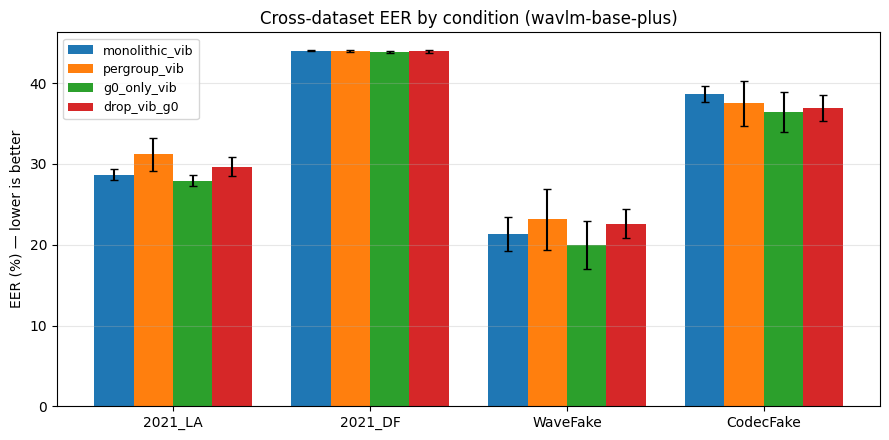

In [19]:
import matplotlib.pyplot as plt
import numpy as np

backbone = 'wavlm-base-plus'
conditions_to_plot = ['monolithic_vib', 'pergroup_vib', 'g0_only_vib', 'drop_vib_g0']
datasets_present = [d for d in DATASET_ORDER if d in df['dataset'].unique()]

x = np.arange(len(datasets_present))
width = 0.8 / max(1, len(conditions_to_plot))

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, cond in enumerate(conditions_to_plot):
    means, stds = [], []
    for ds in datasets_present:
        r = mean_eer(cond, backbone, ds)
        if r is None:
            means.append(np.nan); stds.append(0)
        else:
            m, s, _ = r
            means.append(m); stds.append(s)
    ax.bar(x + i * width, means, width, yerr=stds, label=cond, capsize=3)

ax.set_xticks(x + width * (len(conditions_to_plot) - 1) / 2)
ax.set_xticklabels(datasets_present)
ax.set_ylabel('EER (%) — lower is better')
ax.set_title(f'Cross-dataset EER by condition ({backbone})')
ax.legend(loc='upper left', fontsize=9)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
out_png = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eer_bars.png')
fig.savefig(out_png, dpi=150)
print(f'Saved {out_png}')
plt.show()


Saved /content/drive/MyDrive/Jakob/Experiments/cross_dataset_eer_heatmap.png


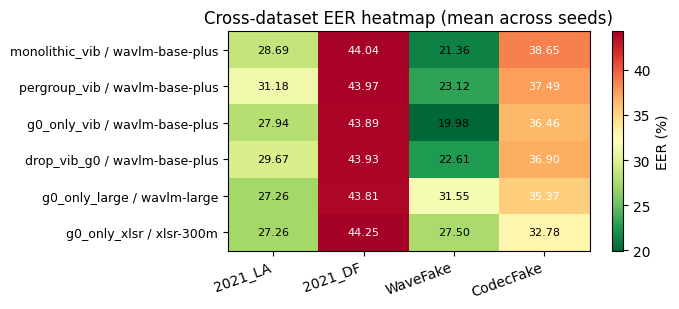

In [20]:
# Heatmap: condition (rows) × dataset (cols), cell = mean EER.
import numpy as np

heatmap_conditions = ['monolithic_vib', 'pergroup_vib', 'g0_only_vib', 'drop_vib_g0',
                      'g0_only_large', 'g0_only_xlsr']
matrix = []
backbones_for_row = []
labels = []
for cond in heatmap_conditions:
    sub_b = df[df['condition'] == cond]['backbone'].unique()
    for bb in sub_b:
        row = []
        for ds in datasets_present:
            r = mean_eer(cond, bb, ds)
            row.append(np.nan if r is None else r[0])
        matrix.append(row)
        labels.append(f'{cond} / {bb}')

matrix = np.array(matrix, dtype=float)

fig, ax = plt.subplots(figsize=(7, 0.5 + 0.45 * len(labels)))
im = ax.imshow(matrix, aspect='auto', cmap='RdYlGn_r')
ax.set_xticks(range(len(datasets_present)))
ax.set_xticklabels(datasets_present, rotation=20, ha='right')
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=9)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                    color=('white' if v > np.nanmean(matrix) else 'black'),
                    fontsize=8)
plt.colorbar(im, ax=ax, label='EER (%)')
ax.set_title('Cross-dataset EER heatmap (mean across seeds)')
fig.tight_layout()
out_png = os.path.join(DRIVE_EXP_BASE, 'cross_dataset_eer_heatmap.png')
fig.savefig(out_png, dpi=150)
print(f'Saved {out_png}')
plt.show()


## 8. Notes for the report

- The pivot table (`cross_dataset_eval_pgvib_pivot.csv`) drops directly into the
  cross-dataset section of the thesis — copy-paste into the LaTeX table.
- The `delta_df` table above is the source for the "PGVIB vs monolithic" sentence
  in the verdict paragraph.
- If per-group VIB wins on a *minority* of datasets but with a large mean delta,
  reconsider `MARGIN` and document the choice.
